In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import folium
from folium.plugins import MarkerCluster

sns.set_style("whitegrid")
%matplotlib inline
df = pd.read_csv(r"C:\Users\verny\Downloads\Tourist_Spots.csv")
print(df.shape)
df.head()

(459, 5)


,DestinationID,Name,Latitude,Longitude,Characteristics
0,1,Munnar Tea Garden View Point,10.042106,77.039940,"scenic, tea, photography"
1,2,Pomathendu Munnar Tea Garden View,10.059649,77.063960,"scenic, tea, photography"
2,3,Munnar Pothamendu,10.036556,77.076797,"tea, greenery, serene"
3,4,Munnar Tea Hill Hiking Spot,10.028382,77.045574,"trekking, nature, adventure"
4,5,Wonder Valley Adventure Amusement Park Munnar,10.027159,77.035570,"adventure, amusement, family"


In [3]:
print("Размер:", df.shape)
df.info()
df.describe()
df.isnull().sum()
print("Дубликатов:", df.duplicated().sum())
df.head()
df.tail()

Размер: (459, 5)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 459 entries, 0 to 458
Data columns (total 5 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   DestinationID    459 non-null    int64  
 1   Name             459 non-null    object 
 2   Latitude         459 non-null    float64
 3   Longitude        459 non-null    float64
 4   Characteristics  459 non-null    object 
dtypes: float64(2), int64(1), object(2)
memory usage: 18.1+ KB
Дубликатов: 0


,DestinationID,Name,Latitude,Longitude,Characteristics
454,455,KanialtoSalin and Lamadugh Top and Kanpari Tib...,32.213575,77.159260,"adventure, nature"
455,456,Kanial Top Boulder Trail,32.237196,77.165338,"nature, adventure"
456,457,Dzongsar Khyentse Chokyi LodroMonastery and Co...,32.006953,76.737861,education
457,458,Dharamshala Kotwali Bazaar,32.216607,76.318204,"shopping, market"
458,459,Nhagsu Naag Triund Trek,32.266375,76.348800,"trekking, adventure, nature"


In [5]:
df.columns = df.columns.str.strip()
df['tags_list'] = df['Characteristics'].fillna('').str.split(', ')
df['n_tags'] = df['tags_list'].apply(len)
cities = ['Munnar','Manali','Dharamshala','Bangalore','Delhi','Mumbai',
          'Chennai','Kolkata','Hyderabad','Pune','Kochi','Jaipur','Goa',
          'Chandigarh','Coimbatore','Guwahati','Palakkad']
def detect_city(name):
    for c in cities:
        if c.lower() in str(name).lower():
            return c
    return 'Other'
df['City'] = df['Name'].apply(detect_city)
print("Размер:", df.shape)
print("\nРаспределение по городам:")
print(df['City'].value_counts())
print("\nСтатистика по количеству тегов:")
print(df['n_tags'].describe())

Размер: (459, 8)

Распределение по городам:
City
Other          371
Delhi           23
Manali          20
Munnar          15
Dharamshala     10
Kolkata          9
Bangalore        3
Guwahati         3
Palakkad         2
Chandigarh       2
Pune             1
Name: count, dtype: int64

Статистика по количеству тегов:
count    459.000000
mean       2.481481
std        0.687684
min        1.000000
25%        2.000000
50%        3.000000
75%        3.000000
max        4.000000
Name: n_tags, dtype: float64


In [7]:
from collections import Counter
all_tags = [t for sub in df['tags_list'] for t in sub if t]
top_tags = pd.Series(Counter(all_tags)).sort_values(ascending=False).head(15)
print("Топ-15 тегов:")
print(top_tags)
print("\nВсего уникальных тегов:", len(set(all_tags)))
print("\nКоординаты:")
print(df[['Latitude','Longitude']].describe())

Топ-15 тегов:
historical       78
photography      71
religious        67
scenic           61
nature           59
architectural    52
spiritual        47
shopping         42
temple           42
fort             27
park             26
market           26
adventure        24
museum           24
waterfall        24
dtype: int64

Всего уникальных тегов: 144

Координаты:
         Latitude   Longitude
count  459.000000  459.000000
mean    19.311054   77.729896
std      8.324287    3.514469
min      8.747832   72.821822
25%     12.272271   76.693868
50%     17.413384   77.130230
75%     28.592166   77.581271
max     32.386711   91.868490


C:\Users\verny\AppData\Local\Temp\ipykernel_18864\909794063.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top_tags.values, y=top_tags.index, palette='viridis')


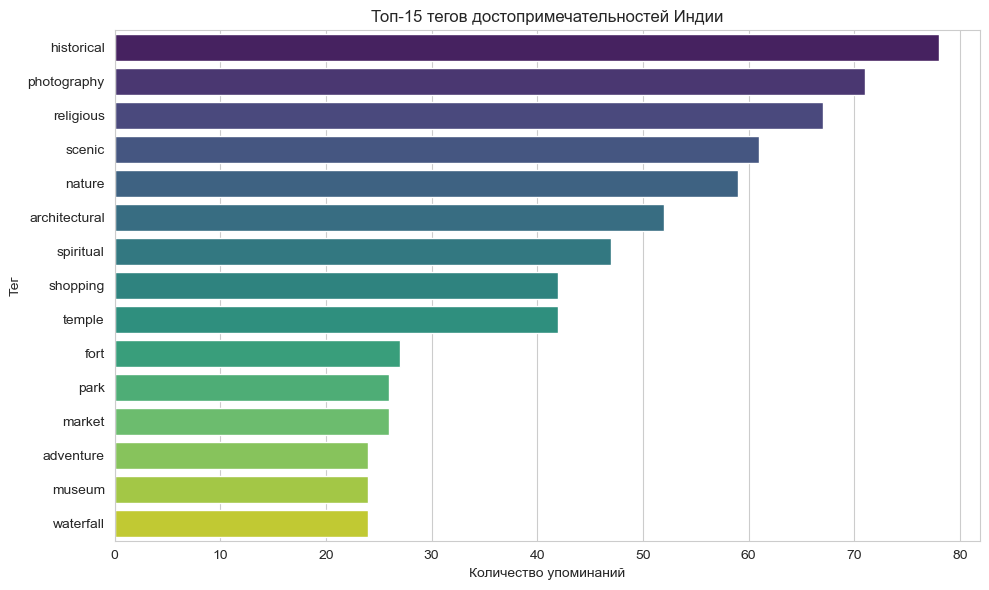

In [8]:
plt.figure(figsize=(10, 6))
sns.barplot(x=top_tags.values, y=top_tags.index, palette='viridis')
plt.title('Топ-15 тегов достопримечательностей Индии')
plt.xlabel('Количество упоминаний')
plt.ylabel('Тег')
plt.tight_layout()
plt.show()

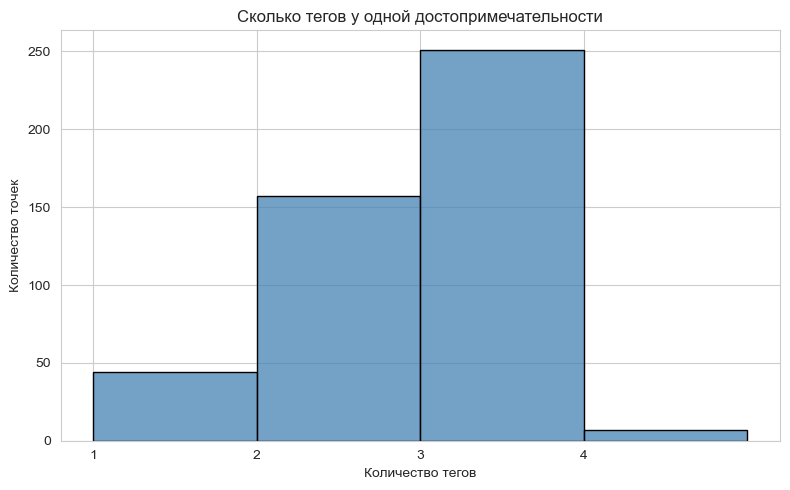

In [9]:
plt.figure(figsize=(8, 5))
sns.histplot(df['n_tags'], bins=range(1, 6), kde=False,
             color='steelblue', edgecolor='black')
plt.title('Сколько тегов у одной достопримечательности')
plt.xlabel('Количество тегов')
plt.ylabel('Количество точек')
plt.xticks(range(1, 5))
plt.tight_layout()
plt.show()

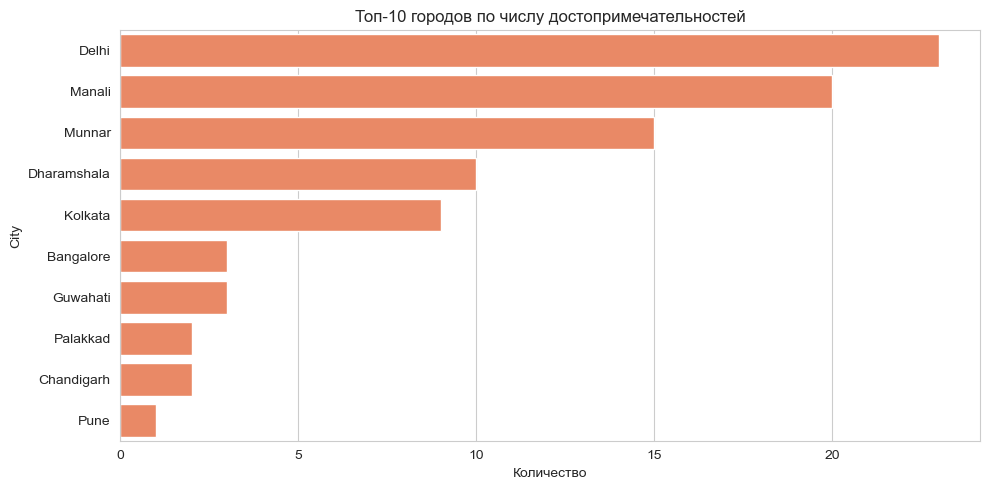

In [11]:
plt.figure(figsize=(10, 5))
city_counts = df[df['City'] != 'Other']['City'].value_counts().head(10)
sns.barplot(x=city_counts.values, y=city_counts.index, color='coral')
plt.title('Топ-10 городов по числу достопримечательностей')
plt.xlabel('Количество')
plt.tight_layout()
plt.show()

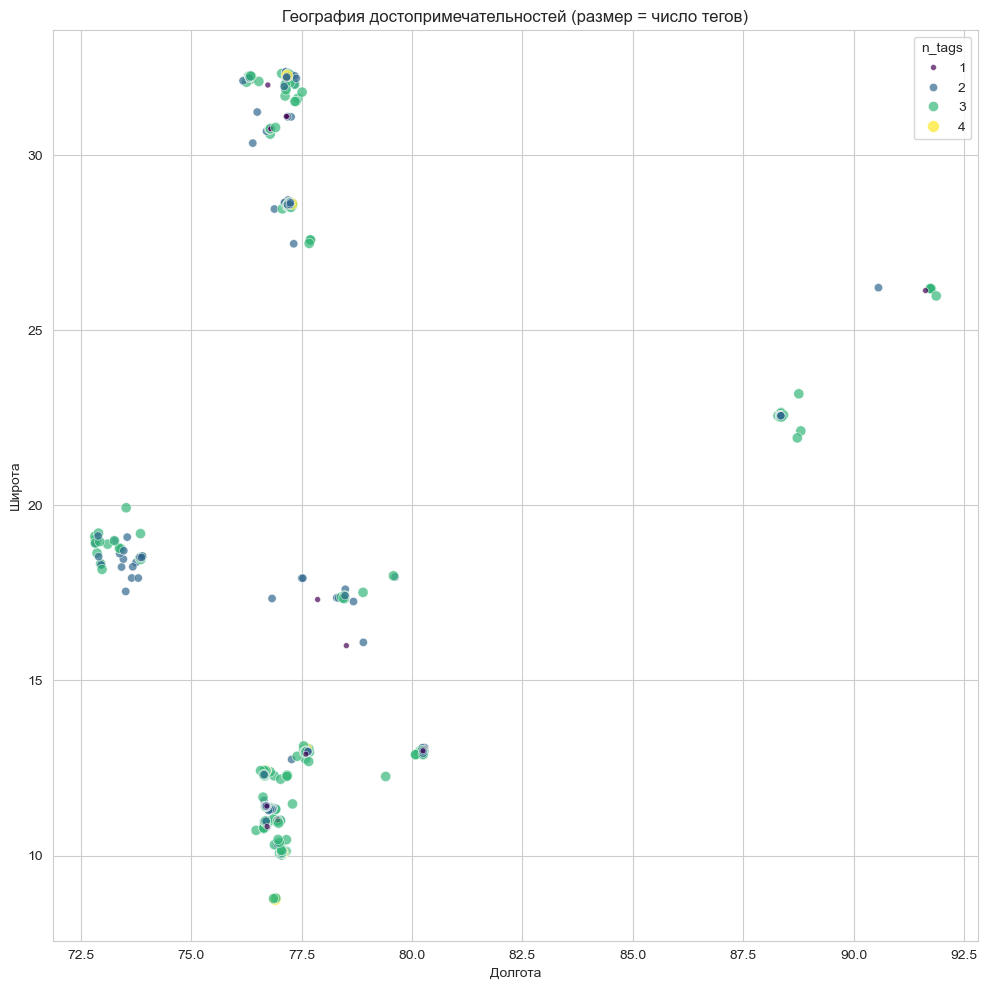

In [14]:
plt.figure(figsize=(10, 10))
sns.scatterplot(data=df, x='Longitude', y='Latitude',
                hue='n_tags', size='n_tags',
                palette='viridis', alpha=0.7)
plt.title('География достопримечательностей (размер = число тегов)')
plt.xlabel('Долгота')
plt.ylabel('Широта')
plt.tight_layout()
plt.show()

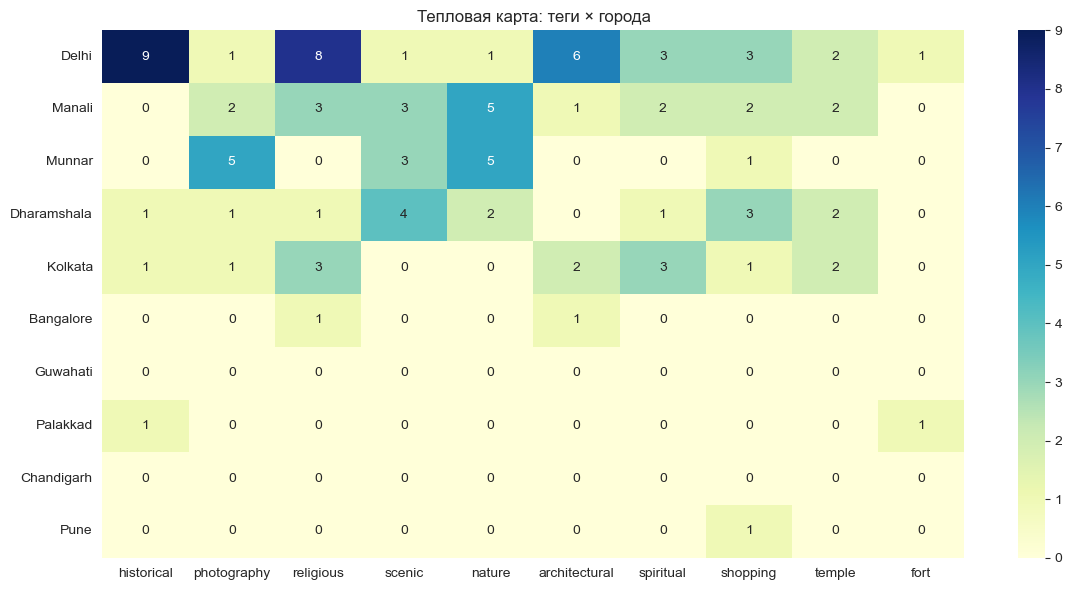

In [15]:
top10_tags = top_tags.head(10).index.tolist()
top10_cities = df[df['City'] != 'Other']['City'].value_counts().head(10).index.tolist()

matrix = pd.DataFrame(0, index=top10_cities, columns=top10_tags)
for _, row in df.iterrows():
    if row['City'] in top10_cities:
        for tag in row['tags_list']:
            if tag in top10_tags:
                matrix.loc[row['City'], tag] += 1

plt.figure(figsize=(12, 6))
sns.heatmap(matrix, annot=True, fmt='d', cmap='YlGnBu')
plt.title('Тепловая карта: теги × города')
plt.tight_layout()
plt.show()

C:\Users\verny\AppData\Local\Temp\ipykernel_18864\1992609898.py:3: DeprecationWarning: *scatter_mapbox* is deprecated! Use *scatter_map* instead. Learn more at: https://plotly.com/python/mapbox-to-maplibre/
  fig = px.scatter_mapbox(


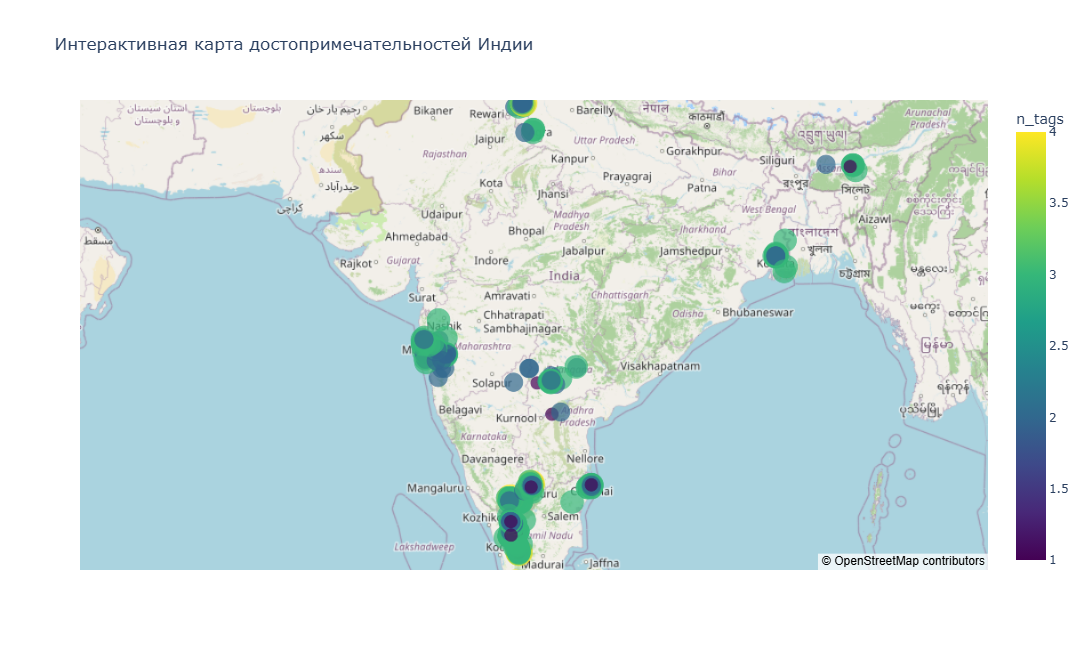

In [16]:
import plotly.express as px

fig = px.scatter_mapbox(
    df,
    lat='Latitude', lon='Longitude',
    color='n_tags', size='n_tags',
    hover_name='Name',
    hover_data={'Characteristics': True, 'Latitude': False, 'Longitude': False},
    color_continuous_scale='Viridis',
    zoom=4, height=650,
    title='Интерактивная карта достопримечательностей Индии'
)
fig.update_layout(mapbox_style='open-street-map')
fig.show()

In [18]:
center = [df['Latitude'].mean(), df['Longitude'].mean()]

m = folium.Map(location=center, zoom_start=5, tiles='OpenStreetMap')
marker_cluster = MarkerCluster(name='Достопримечательности').add_to(m)

for _, row in df.iterrows():
    folium.Marker(
        location=[row['Latitude'], row['Longitude']],
        popup=folium.Popup(
            f"<b>{row['Name']}</b><br>"
            f"<i>Теги:</i> {row['Characteristics']}<br>"
            f"<i>Координаты:</i> {row['Latitude']:.3f}, {row['Longitude']:.3f}",
            max_width=300
        ),
        tooltip=row['Name'],
        icon=folium.Icon(color='blue', icon='info-sign')
    ).add_to(marker_cluster)

folium.LayerControl().add_to(m)
m.save('tourist_map.html')
m